In [142]:
import pandas as pd
data = pd.read_csv("rainfall in india 1901-2015.csv")
print(data.head)

<bound method NDFrame.head of                     SUBDIVISION  YEAR   JAN    FEB   MAR    APR    MAY    JUN  \
0     ANDAMAN & NICOBAR ISLANDS  1901  49.2   87.1  29.2    2.3  528.8  517.5   
1     ANDAMAN & NICOBAR ISLANDS  1902   0.0  159.8  12.2    0.0  446.1  537.1   
2     ANDAMAN & NICOBAR ISLANDS  1903  12.7  144.0   0.0    1.0  235.1  479.9   
3     ANDAMAN & NICOBAR ISLANDS  1904   9.4   14.7   0.0  202.4  304.5  495.1   
4     ANDAMAN & NICOBAR ISLANDS  1905   1.3    0.0   3.3   26.9  279.5  628.7   
...                         ...   ...   ...    ...   ...    ...    ...    ...   
4111                LAKSHADWEEP  2011   5.1    2.8   3.1   85.9  107.2  153.6   
4112                LAKSHADWEEP  2012  19.2    0.1   1.6   76.8   21.2  327.0   
4113                LAKSHADWEEP  2013  26.2   34.4  37.5    5.3   88.3  426.2   
4114                LAKSHADWEEP  2014  53.2   16.1   4.4   14.9   57.4  244.1   
4115                LAKSHADWEEP  2015   2.2    0.5   3.7   87.1  133.1  296.6  

In [143]:
!pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)




In [2]:


df = pd.read_csv("rainfall in india 1901-2015.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())




First 5 rows:
                 SUBDIVISION  YEAR   JAN    FEB   MAR    APR    MAY    JUN  \
0  ANDAMAN & NICOBAR ISLANDS  1901  49.2   87.1  29.2    2.3  528.8  517.5   
1  ANDAMAN & NICOBAR ISLANDS  1902   0.0  159.8  12.2    0.0  446.1  537.1   
2  ANDAMAN & NICOBAR ISLANDS  1903  12.7  144.0   0.0    1.0  235.1  479.9   
3  ANDAMAN & NICOBAR ISLANDS  1904   9.4   14.7   0.0  202.4  304.5  495.1   
4  ANDAMAN & NICOBAR ISLANDS  1905   1.3    0.0   3.3   26.9  279.5  628.7   

     JUL    AUG    SEP    OCT    NOV    DEC  ANNUAL  Jan-Feb  Mar-May  \
0  365.1  481.1  332.6  388.5  558.2   33.6  3373.2    136.3    560.3   
1  228.9  753.7  666.2  197.2  359.0  160.5  3520.7    159.8    458.3   
2  728.4  326.7  339.0  181.2  284.4  225.0  2957.4    156.7    236.1   
3  502.0  160.1  820.4  222.2  308.7   40.1  3079.6     24.1    506.9   
4  368.7  330.5  297.0  260.7   25.4  344.7  2566.7      1.3    309.7   

   Jun-Sep  Oct-Dec  
0   1696.3    980.3  
1   2185.9    716.7  
2   1874.0  

In [3]:


# Select only the required columns
data = df[['SUBDIVISION', 'YEAR', 'ANNUAL']].copy()

# Remove rows where target rainfall is missing
data = data.dropna(subset=['ANNUAL'])

# Handle missing input values
data = data.dropna(subset=['SUBDIVISION', 'YEAR'])

# Convert year into integer
data['YEAR'] = data['YEAR'].astype(int)

print("\nCleaned dataset:")
print(data.head())

print("\nRemaining missing values:")
print(data.isnull().sum())





Cleaned dataset:
                 SUBDIVISION  YEAR  ANNUAL
0  ANDAMAN & NICOBAR ISLANDS  1901  3373.2
1  ANDAMAN & NICOBAR ISLANDS  1902  3520.7
2  ANDAMAN & NICOBAR ISLANDS  1903  2957.4
3  ANDAMAN & NICOBAR ISLANDS  1904  3079.6
4  ANDAMAN & NICOBAR ISLANDS  1905  2566.7

Remaining missing values:
SUBDIVISION    0
YEAR           0
ANNUAL         0
dtype: int64


In [ ]:


# Descriptive statistics
print("\nStatistical Summary:")
print(data.describe())

# Unique subdivisions
print("\nNumber of subdivisions:")
print(data['SUBDIVISION'].nunique())

# Correlation analysis
print("\nCorrelation:")
print(data[['YEAR', 'ANNUAL']].corr())

plt.figure(figsize=(6, 4))
sns.heatmap(
    data[['YEAR', 'ANNUAL']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Heatmap")
plt.show()




In [4]:


X = data[['SUBDIVISION', 'YEAR']]

# Target variable
y = data['ANNUAL']


# Use earlier years for training and later years for testing
unique_years = sorted(data['YEAR'].unique())

split_index = int(len(unique_years) * 0.80)

split_year = unique_years[split_index - 1]

train_data = data[data['YEAR'] <= split_year]
test_data = data[data['YEAR'] > split_year]

X_train = train_data[['SUBDIVISION', 'YEAR']]
X_test = test_data[['SUBDIVISION', 'YEAR']]

y_train = train_data['ANNUAL']
y_test = test_data['ANNUAL']

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Last training year:", split_year)
print("First testing year:", test_data['YEAR'].min())





Training samples: 3265
Testing samples: 825
Last training year: 1992
First testing year: 1993


In [5]:



# 7. DATA PREPROCESSING FOR MODEL

# Convert subdivision names into numerical representation
preprocessor = ColumnTransformer(
    transformers=[
        ('subdivision',
         OneHotEncoder(handle_unknown='ignore'),
         ['SUBDIVISION'])
    ],
    remainder='passthrough'
)




In [6]:


model = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])


def train_model():

    model.fit(X_train, y_train)

    print("\nModel training completed successfully!")



def test_model():

    predictions = model.predict(X_test)

    return predictions



train_model()



y_pred = test_model()



def evaluate_model(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    print("\n MODEL EVALUATION ")

    print("Mean Absolute Error (MAE):", round(mae, 2))

    print("Mean Squared Error (MSE):", round(mse, 2))

    print("Root Mean Squared Error (RMSE):", round(rmse, 2))

    print("R2 Score:", round(r2, 4))

    print("Accuracy-like R2 percentage:", round(r2 * 100, 2), "%")


evaluate_model(y_test, y_pred)





Model training completed successfully!

 MODEL EVALUATION 
Mean Absolute Error (MAE): 228.18
Mean Squared Error (MSE): 113484.58
Root Mean Squared Error (RMSE): 336.87
R2 Score: 0.8463
Accuracy-like R2 percentage: 84.63 %


In [7]:


train_predictions = model.predict(X_train)

print("\n========== TRAINING PERFORMANCE ==========")

evaluate_model(y_train, train_predictions)




results = pd.DataFrame({
    'Subdivision': X_test['SUBDIVISION'].values,
    'Year': X_test['YEAR'].values,
    'Actual Rainfall': y_test.values,
    'Predicted Rainfall': y_pred
})

print("\nActual vs Predicted Rainfall:")
print(results.head(15))





========== TRAINING PERFORMANCE ==========

 MODEL EVALUATION 
Mean Absolute Error (MAE): 198.03
Mean Squared Error (MSE): 85852.21
Root Mean Squared Error (RMSE): 293.01
R2 Score: 0.8973
Accuracy-like R2 percentage: 89.73 %

Actual vs Predicted Rainfall:
                  Subdivision  Year  Actual Rainfall  Predicted Rainfall
0   ANDAMAN & NICOBAR ISLANDS  1993           2237.4         2918.645715
1   ANDAMAN & NICOBAR ISLANDS  1994           3262.8         2918.354660
2   ANDAMAN & NICOBAR ISLANDS  1995           3115.4         2918.063606
3   ANDAMAN & NICOBAR ISLANDS  1996           2996.9         2917.772551
4   ANDAMAN & NICOBAR ISLANDS  1997           2755.1         2917.481496
5   ANDAMAN & NICOBAR ISLANDS  1998           2846.4         2917.190442
6   ANDAMAN & NICOBAR ISLANDS  1999           2699.7         2916.899387
7   ANDAMAN & NICOBAR ISLANDS  2000           2763.2         2916.608332
8   ANDAMAN & NICOBAR ISLANDS  2001           3080.9         2916.317278
9   ANDAMAN &

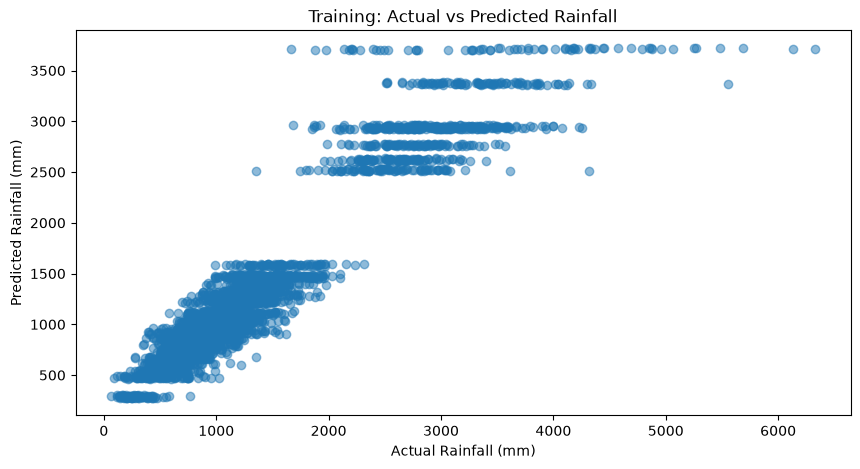

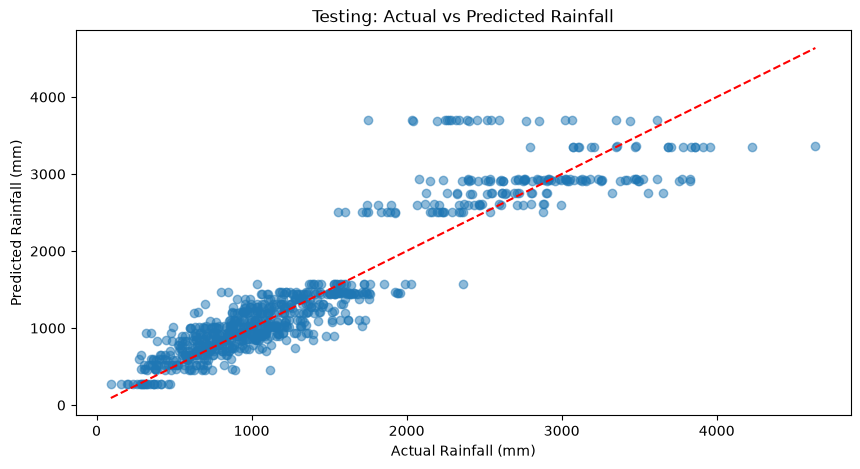

In [8]:

# 16. GRAPH 1: TRAINING DATA

plt.figure(figsize=(10, 5))

plt.scatter(
    y_train,
    train_predictions,
    alpha=0.5
)

plt.xlabel("Actual Rainfall (mm)")
plt.ylabel("Predicted Rainfall (mm)")
plt.title("Training: Actual vs Predicted Rainfall")

plt.show()


# 17. GRAPH 2: TESTING DATA

plt.figure(figsize=(10, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Actual Rainfall (mm)")
plt.ylabel("Predicted Rainfall (mm)")
plt.title("Testing: Actual vs Predicted Rainfall")

# Ideal prediction line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.show()




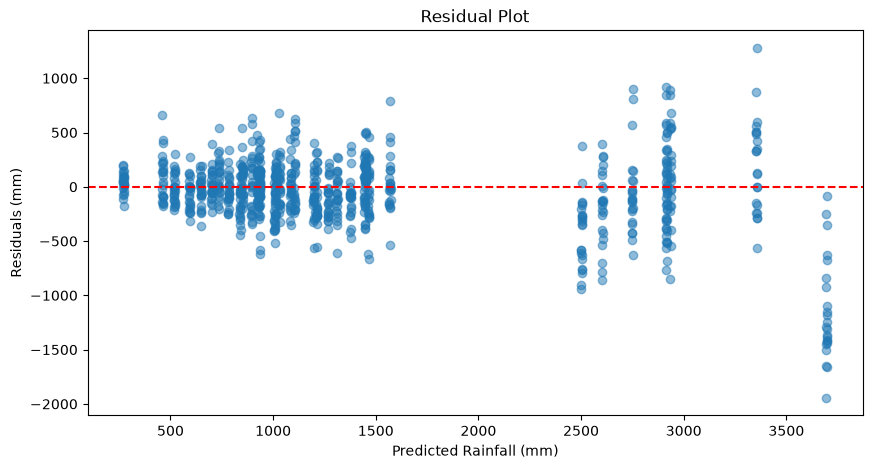

In [9]:



# 18. GRAPH 3: RESIDUAL PLOT

residuals = y_test - y_pred

plt.figure(figsize=(10, 5))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Rainfall (mm)")
plt.ylabel("Residuals (mm)")
plt.title("Residual Plot")

plt.show()




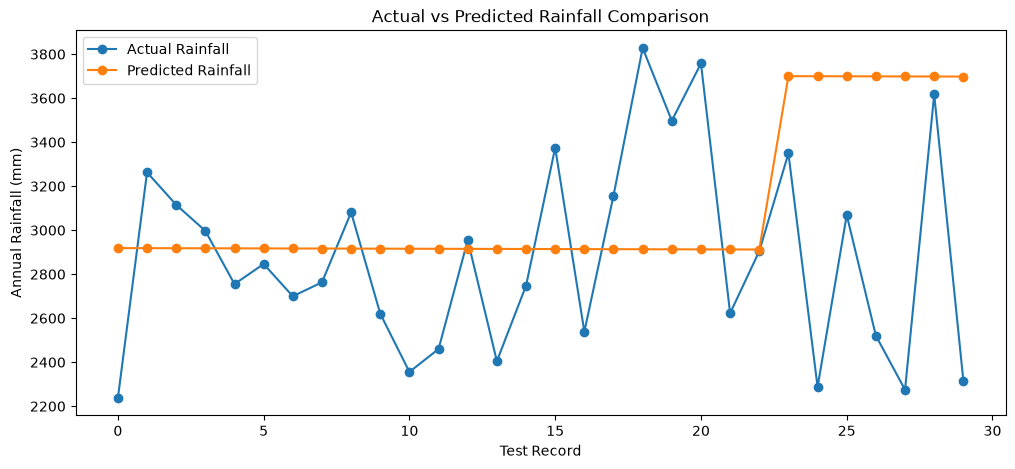

In [10]:



# 19. GRAPH 4: ACTUAL VS PREDICTED FOR SAMPLE TEST RECORDS

comparison = results.head(30)

plt.figure(figsize=(12, 5))

plt.plot(
    range(len(comparison)),
    comparison['Actual Rainfall'],
    marker='o',
    label='Actual Rainfall'
)

plt.plot(
    range(len(comparison)),
    comparison['Predicted Rainfall'],
    marker='o',
    label='Predicted Rainfall'
)

plt.xlabel("Test Record")
plt.ylabel("Annual Rainfall (mm)")
plt.title("Actual vs Predicted Rainfall Comparison")

plt.legend()
plt.show()




In [12]:


print("\n========== RAINFALL PREDICTION ==========")

subdivisions = sorted(data['SUBDIVISION'].unique())

print("\nAvailable subdivisions:")
for s in subdivisions:
    print(s)

while True:

    subdivision = input(
        "\nEnter subdivision name: "
    ).strip().upper()

    if subdivision in subdivisions:
        break

    print("Invalid subdivision! Please enter an available name.")

year = int(input("Enter year for prediction: "))

# Create input DataFrame
new_data = pd.DataFrame({
    'SUBDIVISION': [subdivision],
    'YEAR': [year]
})

# Predict rainfall
predicted_rainfall = model.predict(new_data)


print("RAINFALL PREDICTION RESULT")
print("Subdivision:", subdivision)
print("Year:", year)
print("Predicted Annual Rainfall:",
      round(predicted_rainfall[0], 2), "mm")


========== RAINFALL PREDICTION ==========

Available subdivisions:
ANDAMAN & NICOBAR ISLANDS
ARUNACHAL PRADESH
ASSAM & MEGHALAYA
BIHAR
CHHATTISGARH
COASTAL ANDHRA PRADESH
COASTAL KARNATAKA
EAST MADHYA PRADESH
EAST RAJASTHAN
EAST UTTAR PRADESH
GANGETIC WEST BENGAL
GUJARAT REGION
HARYANA DELHI & CHANDIGARH
HIMACHAL PRADESH
JAMMU & KASHMIR
JHARKHAND
KERALA
KONKAN & GOA
LAKSHADWEEP
MADHYA MAHARASHTRA
MATATHWADA
NAGA MANI MIZO TRIPURA
NORTH INTERIOR KARNATAKA
ORISSA
PUNJAB
RAYALSEEMA
SAURASHTRA & KUTCH
SOUTH INTERIOR KARNATAKA
SUB HIMALAYAN WEST BENGAL & SIKKIM
TAMIL NADU
TELANGANA
UTTARAKHAND
VIDARBHA
WEST MADHYA PRADESH
WEST RAJASTHAN
WEST UTTAR PRADESH
Invalid subdivision! Please enter an available name.
Invalid subdivision! Please enter an available name.
RAINFALL PREDICTION RESULT
Subdivision: EAST RAJASTHAN
Year: 2010
Predicted Annual Rainfall: 646.43 mm
